In [35]:
from sbcbinaryformat import Streamer, Writer
import numpy as np
import matplotlib.pyplot as plt

from GetEvent import GetEvent
from GetEvent import GetScint

from scipy import signal

import csv
import pandas as pd

import os

from sklearn.linear_model import RANSACRegressor
from sklearn.linear_model import LinearRegression

import tempfile
import tarfile

import time

import json

from collections import Counter, defaultdict

from matplotlib.lines import Line2D


In [36]:
# Feb
bright_events_Feb = [
    # 20260218_9
    '20260218_9/0', '20260218_9/2', '20260218_9/3', '20260218_9/4',
    '20260218_9/5', '20260218_9/6', '20260218_9/8', '20260218_9/9',

    # 20260218_11
    '20260218_11/0', '20260218_11/3', '20260218_11/5', '20260218_11/9',
    '20260218_11/13', '20260218_11/15', '20260218_11/17',
    '20260218_11/18', '20260218_11/19', '20260218_11/28',
    '20260218_11/29', '20260218_11/31', '20260218_11/33',
    '20260218_11/40', '20260218_11/41', '20260218_11/42',
    '20260218_11/43', '20260218_11/46', '20260218_11/49',

    # 20260218_12
    '20260218_12/0', '20260218_12/3', '20260218_12/5', '20260218_12/6',
    '20260218_12/7', '20260218_12/10', '20260218_12/13',
    '20260218_12/14', '20260218_12/15', '20260218_12/20',
    '20260218_12/22', '20260218_12/25', '20260218_12/26',
    '20260218_12/31', '20260218_12/32', '20260218_12/36',
    '20260218_12/41', '20260218_12/44', '20260218_12/46',
    '20260218_12/47', '20260218_12/48', '20260218_12/49',

    # 20260218_13
    '20260218_13/1', '20260218_13/3', '20260218_13/5', '20260218_13/6',
    '20260218_13/11', '20260218_13/14', '20260218_13/16',
    '20260218_13/19', '20260218_13/22', '20260218_13/23',
    '20260218_13/28', '20260218_13/29', '20260218_13/32',
    '20260218_13/33', '20260218_13/34', '20260218_13/35',
    '20260218_13/36', '20260218_13/41', '20260218_13/45',
    '20260218_13/46', '20260218_13/48',

    # 20260218_14
    '20260218_14/1', '20260218_14/2', '20260218_14/3', '20260218_14/4',
    '20260218_14/5', '20260218_14/6', '20260218_14/7',
    '20260218_14/8', '20260218_14/10', '20260218_14/12',
    '20260218_14/13',

    # 20260209_11
    '20260209_11/0', '20260209_11/2', '20260209_11/5', '20260209_11/6',
    '20260209_11/7', '20260209_11/10', '20260209_11/12',
    '20260209_11/13', '20260209_11/17', '20260209_11/18',
    '20260209_11/20', '20260209_11/25',

    # 20260209_12
    '20260209_12/3', '20260209_12/6', '20260209_12/7', '20260209_12/8',
    '20260209_12/12', '20260209_12/15', '20260209_12/16',
    '20260209_12/20', '20260209_12/21', '20260209_12/24',
    '20260209_12/30', '20260209_12/33', '20260209_12/34',
    '20260209_12/36', '20260209_12/40', '20260209_12/43',
    '20260209_12/45', '20260209_12/46', '20260209_12/47',
    '20260209_12/49',

    # 20260209_13
    '20260209_13/1', '20260209_13/2',

    # 20260212_0
    '20260212_0/1', '20260212_0/3'
]

multiplicity_counts_Feb = [
 2,2,3,2,1,2,1,1,1,1,1,1,2,2,1,
 2,1,1,1,1,2,1,1,1,1,1,1,1,1,1,2,
 1,1,1,1,2,2,1,1,1,1,1,1,1,
 1,1,1,1,1,1,2,1,2,1,3,1,1,1,1,1,1,2,
 2,2,1,1,1,2,2,1,1,2,1,1,1,1,2,2,1,1,1,

      2,1,1,2,2,1,1,1,np.nan,np.nan,
      2,np.nan,3,2,3,1,1,1,2,1,
      1,1,3,1,2,1,1,1,1,2,1,
      4,1,3,4,1]


# Nov 1850, 300ms
bright_events_Nov = ['20251125_6/1', '20251125_6/4', '20251125_6/6', '20251125_6/7', '20251125_6/8', 
                 '20251125_6/9', '20251125_6/10', '20251125_6/11', '20251125_6/12', '20251125_6/13', 
                 '20251125_6/14', '20251125_6/15', '20251125_6/16', '20251125_6/18', '20251125_6/20', 
                 '20251125_6/27', '20251125_6/29', '20251125_6/32', '20251125_6/33', '20251125_6/35', 
                 '20251125_6/36', '20251125_6/37', '20251125_6/38', '20251125_6/41', '20251125_6/43', 
                 '20251125_6/49', '20251125_6/51', '20251125_6/52', '20251125_6/53', '20251125_6/54', 
                 '20251125_6/63', '20251125_6/64', '20251125_6/66', '20251125_6/69', '20251125_6/78', 
                 '20251125_6/79', '20251125_6/80', '20251125_6/81', '20251125_6/82', '20251125_6/83', 
                 '20251125_6/91', '20251125_6/92', '20251125_6/97', '20251125_7/1', '20251125_7/3', 
                 '20251125_7/7', '20251125_7/8', '20251125_7/9', '20251125_7/10', '20251125_7/12', 
                 '20251125_7/14', '20251125_7/15', '20251125_7/16', '20251125_7/17', '20251125_7/18', 
                 '20251125_7/19', '20251125_7/20', '20251125_7/22', '20251125_7/23', '20251125_7/24', 
                 '20251125_7/29', '20251125_7/31', '20251125_7/32', '20251125_7/33', '20251125_7/36', 
                 '20251125_7/42', '20251125_7/44', '20251125_7/46', '20251125_7/48', '20251125_7/49', 
                 '20251125_7/52', '20251125_7/53', '20251125_7/56', '20251125_7/57', '20251125_7/58', 
                 '20251125_7/59', '20251125_7/60', '20251125_7/61', '20251125_7/62', '20251125_7/66', 
                 '20251125_7/70', '20251125_7/72', '20251125_7/73', '20251125_7/74', '20251125_7/77', 
                 '20251125_7/78', '20251125_7/80', '20251125_7/83', '20251125_7/84', '20251125_7/86', 
                 '20251125_7/89', '20251125_7/91', '20251125_7/94', '20251125_7/95', '20251125_7/97', 
                 '20251125_7/98', '20251125_7/99', '20251125_8/1', '20251125_8/3', '20251125_8/5', 
                 '20251125_8/8', '20251125_8/9', '20251125_8/10', '20251125_8/12', '20251125_8/13', 
                 '20251125_8/14', '20251125_8/15', '20251125_8/16', '20251125_8/17', '20251125_8/28', 
                 '20251125_8/30', '20251125_8/32', '20251125_8/37', '20251125_8/38', '20251125_8/39', 
                 '20251125_8/42', '20251125_8/44', '20251125_8/45', '20251125_8/46', '20251125_8/48', 
                 '20251125_8/50', '20251125_8/51', '20251125_8/53', '20251125_8/55', '20251125_8/56', 
                 '20251125_8/57', '20251125_8/58', '20251125_8/59', '20251125_8/60', '20251125_8/61', 
                 '20251125_8/69', '20251125_8/72', '20251125_8/73', '20251125_8/75', '20251125_8/79', 
                 '20251125_8/80', '20251125_8/81', '20251125_8/82', '20251125_8/83', '20251125_8/84', 
                 '20251125_8/86', '20251125_8/87', '20251125_8/89', '20251125_8/93', '20251125_8/94']


multiplicity_counts_Nov = [1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 
                       1, 1, 1, 1, 1, 1, 3, 2, 2, 1, 
                       2, 1, 1, 2, 1, 1, 1, 2, 1, 1, 
                       1, 1, 2, 2, 1, 1, 1, 1, 2, 1, 
                       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 
                       1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 
                       7, 1, 1, 1, 1, 1, 3, 1, 1, 1, 
                       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 
                       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 
                       1, 1, 1, 1, 1, 2, 1, 1, 4, 1, 
                       1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 
                       1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 
                       1, 1, 5, 1, 1, 3, 3, 1, 1, 1, 
                       1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 
                       1, 1, 1, 1, 1]


In [37]:
counts = Counter(multiplicity_counts_Feb)
print("FEB:")
print(len(multiplicity_counts_Feb))
for entry, count in counts.items():
    print(f"{entry}: {count}")
print("")
counts = Counter(multiplicity_counts_Nov)
print("NOV:")
print(len(multiplicity_counts_Nov))
for entry, count in counts.items():
    print(f"{entry}: {count}")


FEB:
117
2: 29
3: 6
1: 77
nan: 3
4: 2

NOV:
145
1: 123
2: 14
3: 5
7: 1
4: 1
5: 1


In [38]:
# Separate by pset
base_dir = "/exp/e961/data/SBC-25-recon/v1.0.0"

# Feb
events_by_pressureFeb = defaultdict(list)
multiplicities_by_pressureFeb = defaultdict(list)

for run_event, multiplicity in zip(bright_events_Feb, multiplicity_counts_Feb):
    runid, event = run_event.split('/')

    event_file = os.path.join(base_dir, runid, "event.sbc")
    event_data = Streamer(event_file).to_dict()

    event_pressure = np.asarray(event_data["pset_lo"])

    pset = event_pressure[int(event)]

    events_by_pressureFeb[pset].append(run_event)
    multiplicities_by_pressureFeb[pset].append(multiplicity)


# Nov
events_by_pressureNov = defaultdict(list)
multiplicities_by_pressureNov = defaultdict(list)

for run_event, multiplicity in zip(bright_events_Nov, multiplicity_counts_Nov):
    runid, event = run_event.split('/')

    event_file = os.path.join(base_dir, runid, "event.sbc")
    event_data = Streamer(event_file).to_dict()

    event_pressure = np.asarray(event_data["pset_lo"])

    pset = event_pressure[int(event)]

    events_by_pressureNov[pset].append(run_event)
    multiplicities_by_pressureNov[pset].append(multiplicity)

In [39]:
for pset in sorted(events_by_pressureFeb.keys()):
    print(f"Pressure: {pset} | "f"Events: {len(events_by_pressureFeb[pset])}")
print("")
for pset in sorted(events_by_pressureNov.keys()):
    print(f"Pressure: {pset} | "f"Events: {len(events_by_pressureNov[pset])}")

Pressure: 1.5 | Events: 35
Pressure: 2.0 | Events: 30
Pressure: 2.5 | Events: 11
Pressure: 3.0 | Events: 12
Pressure: 4.0 | Events: 14
Pressure: 5.0 | Events: 15

Pressure: 2.25 | Events: 28
Pressure: 2.5 | Events: 24
Pressure: 3.0 | Events: 25
Pressure: 3.5 | Events: 29
Pressure: 4.0 | Events: 27
Pressure: 4.5 | Events: 12


In [40]:
print(events_by_pressureNov)
print(multiplicities_by_pressureNov)

defaultdict(<class 'list'>, {np.float32(2.5): ['20251125_6/1', '20251125_6/8', '20251125_6/13', '20251125_6/29', '20251125_7/3', '20251125_7/8', '20251125_7/10', '20251125_7/12', '20251125_7/17', '20251125_7/33', '20251125_7/58', '20251125_7/95', '20251125_8/13', '20251125_8/16', '20251125_8/32', '20251125_8/37', '20251125_8/38', '20251125_8/44', '20251125_8/45', '20251125_8/46', '20251125_8/56', '20251125_8/60', '20251125_8/89', '20251125_8/93'], np.float32(4.0): ['20251125_6/4', '20251125_6/16', '20251125_6/27', '20251125_6/38', '20251125_6/43', '20251125_6/54', '20251125_6/66', '20251125_6/69', '20251125_6/92', '20251125_7/22', '20251125_7/36', '20251125_7/42', '20251125_7/46', '20251125_7/60', '20251125_7/80', '20251125_7/83', '20251125_7/86', '20251125_7/91', '20251125_7/94', '20251125_7/99', '20251125_8/30', '20251125_8/51', '20251125_8/53', '20251125_8/57', '20251125_8/72', '20251125_8/75', '20251125_8/94'], np.float32(3.5): ['20251125_6/6', '20251125_6/7', '20251125_6/10', '202

In [41]:
'''
pset: mult1, 2, 3, 4+
2.25: 25,3,0,0
2.5: 22,1,1,0
3.0: 22,2,0,1
3.5: 22,5,1,1
4.0: 23,2,1,1
4.5: 9,1,2,0
'''
'''
Pressure counts (all "good" events in Nov1850):
2.25: 41
2.5: 46
3.0: 44
3.5: 49
4.0: 44
4.5: 30
'''

'\nPressure counts (all "good" events in Nov1850):\n2.25: 41\n2.5: 46\n3.0: 44\n3.5: 49\n4.0: 44\n4.5: 30\n'

In [42]:
# OLD
'''
pres_lt_Feb = {1.5: 23.052350, 2.00: 25.924054, 2.25: 27.337269, 2.50: 27.322856, 3.00: 34.076887, 3.50: 46.868743,
              4.00: 44.162915, 4.50: 56.885400, 5.00: 60.947413}


pres_lt_Nov = {1.5: 45.185719, 1.75: 46.793523, 2.00: 60.091417, 2.25: 58.296248, 2.50: 60.762101, 3.00: 67.457373, 3.50: 79.052914,
              4.00: 83.028328, 4.50: 89.818504, 5.00: 89.684427}
'''

'\npres_lt_Feb = {1.5: 23.052350, 2.00: 25.924054, 2.25: 27.337269, 2.50: 27.322856, 3.00: 34.076887, 3.50: 46.868743,\n              4.00: 44.162915, 4.50: 56.885400, 5.00: 60.947413}\n\n\npres_lt_Nov = {1.5: 45.185719, 1.75: 46.793523, 2.00: 60.091417, 2.25: 58.296248, 2.50: 60.762101, 3.00: 67.457373, 3.50: 79.052914,\n              4.00: 83.028328, 4.50: 89.818504, 5.00: 89.684427}\n'

In [43]:
# S1 (Nov) is config 1, 116.7 K
pres_lt_Nov = {1.5: 7.967118957993552897e+01, 1.75: 7.693372495755511409e+01, 2.00: 5.990872255400694968e+01, 
              2.25: 5.960700844957946742e+01, 2.50: 5.903832482696034134e+01, 3.00: 5.297608971394218713e+01, 
              3.50: 4.753906908421696897e+01, 4.00: 3.634765741825334828e+01, 4.50: 3.874525515182162394e+01, 
              5.00: 4.014074806502446080e+01}

# S2 (Feb) is config 3, 119.6 K

pres_lt_Feb = {1.5: 1.506798271764703259e+02, 2.00: 1.401063366080495598e+02, 2.25: 1.316883567091143163e+02, 
              2.50: 1.317003013914516600e+02, 3.00: 1.045726890812128715e+02, 3.50: 7.681025301776895731e+01,
              4.00: 8.404293452965501388e+01, 4.50: 6.328513072823438534e+01, 5.00: 6.180544777790436228e+01}

'''
Pressure counts (all "good" events in S2):
1.5: 74
2.0: 63
2.5: 22
3.0: 24
4.0: 25
5.0: 24
'''
'''
Pressure counts (all "good" events in Nov1850):
2.25: 41
2.5: 46
3.0: 44
3.5: 49
4.0: 44
4.5: 30
'''
Feb_full_pcounts = {1.5: 74, 2.0: 63, 2.5: 22, 3.0: 24, 4.0: 25, 5.0: 24}
Nov_full_pcounts = {2.25: 41, 2.5: 46, 3.0: 44, 3.5: 49, 4.0: 44, 4.5: 30}

In [44]:
# Convert from 1/hour to seconds
pres_lt_Nov = {pressure: 3600 / rate for pressure, rate in pres_lt_Nov.items()}

pres_lt_Feb = {pressure: 3600 / rate for pressure, rate in pres_lt_Feb.items()}
print(pres_lt_Nov)

{1.5: 45.1857191913528, 1.75: 46.793522632449495, 2.0: 60.09141651709642, 2.25: 60.39558256048326, 2.5: 60.97733989830331, 3.0: 67.95518543250571, 3.5: 75.72718753963157, 4.0: 99.04352180319945, 4.5: 92.91460298541213, 5.0: 89.68442726000818}


In [45]:
with open("/exp/e961/data/users/gputnam/final-rates-8-20/background_final_rates.txt", "r") as file:
    contents = file.read()

print(contents)

# Pressure [bara]	Temperature [K]	Seitz Threshold [keV]	Eion [keV]	rion [nm]	rho_l [g/cc]	Rate [/hr]	Rate Error [/hr]	Bulk Rate [/hr]	Bulk Rate Error [/hr]	Wall Rate [/hr]	Wall Rate Error [/hr]	Dome Rate [/hr]	Dome Rate Error [/hr]	Bottom Rate [/hr]	Bottom Rate Error [/hr]
1.500000000000000000e+00 1.167000000000000028e+02 8.941449119754344421e-01 4.872794843548647892e-01 4.803372167121699121e+00 1.183965924506307665e+00 7.967118957993552897e+01 1.220189389962975923e+01 3.186847583197421230e+01 6.849684573140599753e+00 1.348281669814293693e+01 4.236116951796339514e+00 1.715994852490919342e+01 4.824709869903480275e+00 1.715994852490919342e+01 4.824709869903480275e+00
1.500000000000000000e+00 1.195999999999999943e+02 4.598182881878970507e-01 2.668860430715899734e-01 3.795139271371309242e+00 1.157230608217096668e+00 1.506798271764703259e+02 8.295686180886743699e+00 8.280603115103325251e+01 6.781446088790369586e+00 1.832592492686801222e+01 3.458327870919819080e+00 3.122194617170105602e+01 4

In [46]:
# S2 (Feb) is config 3, 119.6 K

pres_lt_Feb = {1.5: 1.506798271764703259e+02, 2.00: 1.401063366080495598e+02, 2.25: 1.316883567091143163e+02, 
              2.50: 1.317003013914516600e+02, 3.00: 1.045726890812128715e+02, 3.50: 7.681025301776895731e+01,
              4.00: 8.404293452965501388e+01, 4.50: 6.328513072823438534e+01, 5.00: 6.180544777790436228e+01}

Q_Feb = {1.5: 4.598182881878970507e-01, 2.00: 5.194761325266749052e-01, 2.25: 5.536006740173549101e-01, 
              2.50: 5.910772395808175927e-01, 3.00: 6.779188629558312584e-01, 3.50: 7.844852772759595139e-01,
              4.00: 9.169869609564831325e-01, 4.50: 1.084202336206221640e+00, 5.00: 1.298829194074205606e+00}

# Nov 1850 is config 1, 116.7 K

pres_lt_Nov = {1.5: 7.967118957993552897e+01, 1.75: 7.693372495755511409e+01, 2.00: 5.990872255400694968e+01, 
              2.25: 5.960700844957946742e+01, 2.50: 5.903832482696034134e+01, 2.75: 7.307096910154061220e+01,
              3.00: 5.297608971394218713e+01, 3.50: 4.753906908421696897e+01, 4.00: 3.634765741825334828e+01,
              4.50: 3.874525515182162394e+01, 5.00: 4.014074806502446080e+01}

Q_Nov = {1.5: 8.941449119754344421e-01, 1.75: 9.633292631922287796e-01, 2.00: 1.040505302598664805e+00, 
         2.25: 1.126908955214469321e+00, 2.50: 1.224018040650277639e+00, 2.75: 1.333610081481736875e+00,
         3.00: 1.457836740123748864e+00, 3.50: 1.761279285559721020e+00, 4.00: 2.163539775039333257e+00,
         4.50: 2.710223411385844106e+00, 5.00: 3.475391362230860093e+00}


In [47]:
# Convert from 1/hour to seconds
pres_lt_Nov = {pressure: 3600 / rate for pressure, rate in pres_lt_Nov.items()}

pres_lt_Feb = {pressure: 3600 / rate for pressure, rate in pres_lt_Feb.items()}
print(pres_lt_Nov)

{1.5: 45.1857191913528, 1.75: 46.793522632449495, 2.0: 60.09141651709642, 2.25: 60.39558256048326, 2.5: 60.97733989830331, 2.75: 49.2671719598707, 3.0: 67.95518543250571, 3.5: 75.72718753963157, 4.0: 99.04352180319945, 4.5: 92.91460298541213, 5.0: 89.68442726000818}


In [48]:
# Full event counts at each PSET
Feb_full_pcounts = {1.5: 74, 2.0: 63, 2.5: 22, 3.0: 24, 4.0: 25, 5.0: 24}

psets = sorted(Feb_full_pcounts.keys())

multiplicity_labels = ["1", "2", "3", "4+"]
n_bins = len(multiplicity_labels)

width = 0.8 / len(psets)

for i, pset in enumerate(psets):

    data = np.array(multiplicities_by_pressureFeb[pset])

    # Live time for this individual PSET
    event_lt = pres_lt_Feb[pset]
    label = f"Pset = {pset}"

    total_events = Feb_full_pcounts[pset]
    total_live_time = total_events * event_lt

    normalization_factor = 3600 / total_live_time


    counts = np.array([np.sum(data == 1),np.sum(data == 2),np.sum(data == 3),np.sum(data >= 4)])
    rates = counts * normalization_factor

    count_errors = np.sqrt(counts)
    rate_errors = count_errors * normalization_factor


    print("")
    print(f"Pset = {pset}")
    print(f"Relevant events = {len(data)}")
    print(f"Total events = {total_events}")
    print(f"Live time per event = {event_lt:.6f} s")
    print(f"Total live time = {total_live_time:.6f} s")
    print("")

    print("Multiplicity,raw count,rate [events/hour],error")

    for mult, count, rate, error in zip(multiplicity_labels,counts,rates,rate_errors):
        print(f"{mult},{count},{rate:.6f},{error:.6f}")


Pset = 1.5
Relevant events = 35
Total events = 74
Live time per event = 23.891718 s
Total live time = 1767.987162 s

Multiplicity,raw count,rate [events/hour],error
1,19,38.688064,8.875651
2,12,24.434567,7.053652
3,2,4.072428,2.879641
4+,1,2.036214,2.036214

Pset = 2.0
Relevant events = 30
Total events = 63
Live time per event = 25.694769 s
Total live time = 1618.770467 s

Multiplicity,raw count,rate [events/hour],error
1,22,48.926022,10.431063
2,3,6.671730,3.851925
3,2,4.447820,3.145084
4+,1,2.223910,2.223910

Pset = 2.5
Relevant events = 11
Total events = 22
Live time per event = 27.334789 s
Total live time = 601.365366 s

Multiplicity,raw count,rate [events/hour],error
1,5,29.931887,13.385947
2,5,29.931887,13.385947
3,1,5.986377,5.986377
4+,0,0.000000,0.000000

Pset = 3.0
Relevant events = 12
Total events = 24
Live time per event = 34.425815 s
Total live time = 826.219549 s

Multiplicity,raw count,rate [events/hour],error
1,5,21.785977,9.742985
2,6,26.143172,10.672905
3,1,4.357195,

In [49]:
# Full event counts at each PSET
Nov_full_pcounts = {
    2.25: 41,
    2.5: 46,
    3.0: 44,
    3.5: 49,
    4.0: 44,
    4.5: 30
}

psets = sorted(Nov_full_pcounts.keys())

multiplicity_labels = ["1", "2", "3", "4+"]
n_bins = len(multiplicity_labels)

width = 0.8 / len(psets)

for i, pset in enumerate(psets):

    data = np.array(multiplicities_by_pressureNov[pset])

    # Live time for this individual PSET
    event_lt = pres_lt_Nov[pset]
    label = f"Pset = {pset}"

    total_events = Nov_full_pcounts[pset]
    total_live_time = total_events * event_lt

    normalization_factor = 3600 / total_live_time


    counts = np.array([np.sum(data == 1),np.sum(data == 2),np.sum(data == 3),np.sum(data >= 4)])
    rates = counts * normalization_factor

    count_errors = np.sqrt(counts)
    rate_errors = count_errors * normalization_factor


    print("")
    print(f"Pset = {pset}")
    print(f"Relevant events = {len(data)}")
    print(f"Total events = {total_events}")
    print(f"Live time per event = {event_lt:.6f} s")
    print(f"Total live time = {total_live_time:.6f} s")
    print("")

    print("Multiplicity,raw count,rate [events/hour],error")

    for mult, count, rate, error in zip(multiplicity_labels,counts,rates,rate_errors):
        print(f"{mult},{count},{rate:.6f},{error:.6f}")


Pset = 2.25
Relevant events = 28
Total events = 41
Live time per event = 60.395583 s
Total live time = 2476.218885 s

Multiplicity,raw count,rate [events/hour],error
1,25,36.345737,7.269147
2,3,4.361488,2.518107
3,0,0.000000,0.000000
4+,0,0.000000,0.000000

Pset = 2.5
Relevant events = 24
Total events = 46
Live time per event = 60.977340 s
Total live time = 2804.957635 s

Multiplicity,raw count,rate [events/hour],error
1,22,28.235721,6.019876
2,1,1.283442,1.283442
3,1,1.283442,1.283442
4+,0,0.000000,0.000000

Pset = 3.0
Relevant events = 25
Total events = 44
Live time per event = 67.955185 s
Total live time = 2990.028159 s

Multiplicity,raw count,rate [events/hour],error
1,22,26.488045,5.647270
2,2,2.408004,1.702716
3,0,0.000000,0.000000
4+,1,1.204002,1.204002

Pset = 3.5
Relevant events = 29
Total events = 49
Live time per event = 75.727188 s
Total live time = 3710.632189 s

Multiplicity,raw count,rate [events/hour],error
1,22,21.344072,4.550571
2,5,4.850925,2.169400
3,1,0.970185,0.9

In [50]:
0.0108+0.0006

0.0114

In [51]:
0.0057+0.0003

0.006

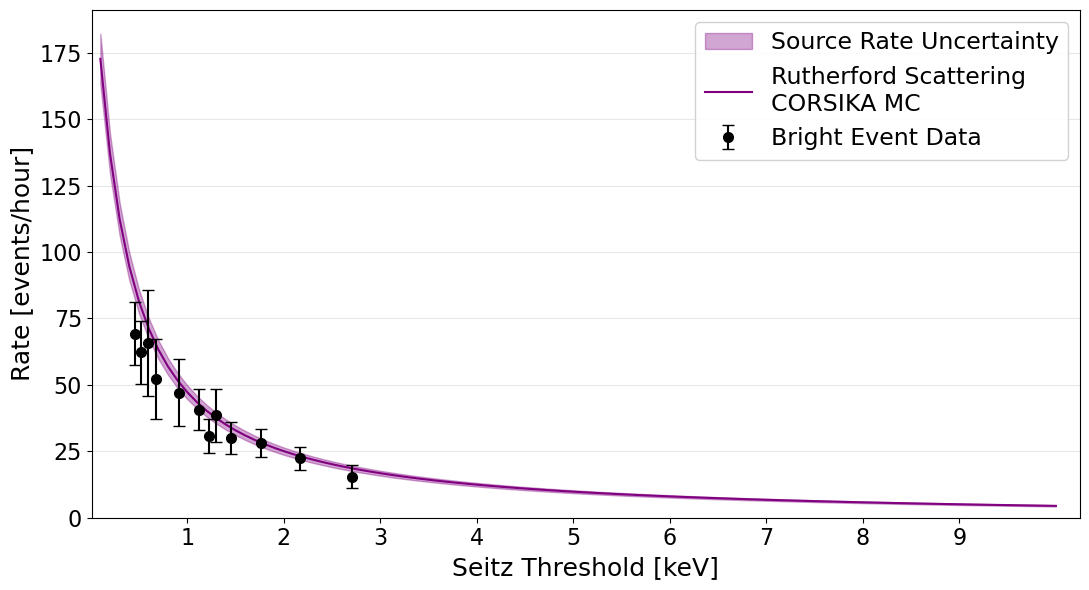

In [52]:
# FEB

# 1.5, 4.598182881878970507e-01 keV
pset_1p5_Feb = np.array([38.688064, 24.434567, 4.072428, 2.036214])
pset_1p5_err_Feb = np.array([8.875651, 7.053652, 2.879641, 2.036214])

# 2.0, 5.194761325266749052e-01 keV
pset_2_Feb = np.array([48.926022, 6.671730, 4.447820, 2.223910])
pset_2_err_Feb = np.array([10.431063, 3.851925, 3.145084, 2.223910])

# 2.5, 5.910772395808175927e-01 keV
pset_2p5_Feb = np.array([29.931887, 29.931887, 5.986377, 0])
pset_2p5_err_Feb = np.array([13.385947, 13.385947, 5.986377, 0])

# 3.0, 6.779188629558312584e-01 keV
pset_3_Feb = np.array([21.785977, 26.143172, 4.357195, 0])
pset_3_err_Feb = np.array([9.742985, 10.672905, 4.357195, 0])

# 4.0, 9.169869609564831325e-01 keV
pset_4_Feb = np.array([36.978891, 10.085152, 0, 0])
pset_4_err_Feb = np.array([11.149555, 5.822665, 0, 0])

# 5.0, 1.298829194074205606e+00 keV
pset_5_Feb = np.array([38.628405, 0, 0, 0])
pset_5_err_Feb = np.array([9.973811, 0, 0, 0])



# NOV

# 2.25, 1.126908955214469321e+00 keV
pset_2p25_Nov = np.array([36.345737, 4.361488, 0, 0])
pset_2p25_err_Nov = np.array([7.269147, 2.518107, 0, 0])

# 2.5, 1.224018040650277639e+00 keV
pset_2p5_Nov = np.array([28.235721, 1.283442, 1.283442, 0])
pset_2p5_err_Nov = np.array([6.019876, 1.283442, 1.283442, 0])

# 3.0, 1.457836740123748864e+00 keV
pset_3_Nov = np.array([26.488045, 2.408004, 0, 1.204002])
pset_3_err_Nov = np.array([5.647270, 1.702716, 0, 1.204002])

# 3.5, 1.761279285559721020e+00 keV
pset_3p5_Nov = np.array([21.344072, 4.850925, 0.970185, 0.970185])
pset_3p5_err_Nov = np.array([4.550571, 2.169400, 0.970185, 0.970185])

# 4.0, 2.163539775039333257e+00 keV
pset_4_Nov = np.array([18.999912, 1.652166, 0.826083, 0.826083])
pset_4_err_Nov = np.array([3.961755, 1.168258, 0.826083, 0.826083])

# 4.5, 2.710223411385844106e+00 keV
pset_4p5_Nov = np.array([11.623577, 1.291509, 2.583017, 0])
pset_4p5_err_Nov = np.array([3.874526, 1.291509, 1.826469, 0])



# MC DATA

mc_100 = np.array([43.2821, 32.3846, 27.0080, 70.0152])
mc_200 = np.array([58.1316, 36.9671, 22.0298, 19.9588])
mc_300 = np.array([61.4687, 30.5999, 13.2778, 7.0091])
mc_400 = np.array([59.6492, 23.8989, 8.0705, 2.9862])
mc_500 = np.array([56.1310, 18.6894, 5.1482, 1.4631])
mc_600 = np.array([52.2591, 14.8379, 3.4452, 0.7939])
mc_700 = np.array([48.5254, 11.9869, 2.4026, 0.4651])
mc_800 = np.array([45.0930, 9.8452, 1.7344, 0.2893])
mc_900 = np.array([41.9970, 8.2073, 1.2888, 0.1887])
mc_1000 = np.array([39.2238, 6.9322, 0.9813, 0.1280])
mc_1100 = np.array([36.7433, 5.9231, 0.7628, 0.0896])
mc_1200 = np.array([34.5214, 5.1125, 0.6036, 0.0644])
mc_1300 = np.array([32.5258, 4.4527, 0.4851, 0.0475])
mc_1400 = np.array([30.7275, 3.9090, 0.3952, 0.0357])
mc_1500 = np.array([29.1010, 3.4562, 0.3258, 0.0272])
mc_1600 = np.array([27.6245, 3.0754, 0.2715, 0.0212])
mc_1700 = np.array([26.2794, 2.7523, 0.2283, 0.0168])
mc_1800 = np.array([25.0497, 2.4760, 0.1937, 0.0132])
mc_1900 = np.array([23.9218, 2.2380, 0.1656, 0.0106])
mc_2000 = np.array([22.8841, 2.0316, 0.1426, 0.0087])
mc_2100 = np.array([21.9264, 1.8515, 0.1235, 0.0071])
mc_2200 = np.array([21.0402, 1.6936, 0.1076, 0.0060])
mc_2300 = np.array([20.2179, 1.5543, 0.0943, 0.0049])
mc_2400 = np.array([19.4531, 1.4310, 0.0830, 0.0042])
mc_2500 = np.array([18.7400, 1.3212, 0.0735, 0.0035])
mc_2600 = np.array([18.0738, 1.2231, 0.0653, 0.0030])
mc_2700 = np.array([17.4500, 1.1351, 0.0582, 0.0026])
mc_2800 = np.array([16.8647, 1.0559, 0.0521, 0.0022])
mc_2900 = np.array([16.3146, 0.9844, 0.0468, 0.0019])
mc_3000 = np.array([15.7967, 0.9196, 0.0422, 0.0017])
mc_3100 = np.array([15.3083, 0.8608, 0.0381, 0.0014])
mc_3200 = np.array([14.8469, 0.8071, 0.0345, 0.0012])
mc_3300 = np.array([14.4104, 0.7582, 0.0314, 0.0011])
mc_3400 = np.array([13.9969, 0.7133, 0.0286, 0.0010])
mc_3500 = np.array([13.6047, 0.6721, 0.0261, 0.0008])
mc_3600 = np.array([13.2321, 0.6343, 0.0239, 0.0007])
mc_3700 = np.array([12.8778, 0.5993, 0.0219, 0.0007])
mc_3800 = np.array([12.5405, 0.5671, 0.0202, 0.0006])
mc_3900 = np.array([12.2189, 0.5373, 0.0186, 0.0005])
mc_4000 = np.array([11.9121, 0.5096, 0.0171, 0.0005])
mc_4100 = np.array([11.6190, 0.4839, 0.0158, 0.0004])
mc_4200 = np.array([11.3387, 0.4600, 0.0147, 0.0004])
mc_4300 = np.array([11.0706, 0.4378, 0.0136, 0.0004])
mc_4400 = np.array([10.8137, 0.4170, 0.0126, 0.0003])
mc_4500 = np.array([10.5674, 0.3976, 0.0118, 0.0003])
mc_4600 = np.array([10.3311, 0.3795, 0.0109, 0.0003])
mc_4700 = np.array([10.1042, 0.3625, 0.0102, 0.0002])
mc_4800 = np.array([9.8861, 0.3465, 0.0095, 0.0002])
mc_4900 = np.array([9.6764, 0.3315, 0.0089, 0.0002])
mc_5000 = np.array([9.4746, 0.3174, 0.0083, 0.0002])
mc_5100 = np.array([9.2803, 0.3042, 0.0078, 0.0002])
mc_5200 = np.array([9.0930, 0.2917, 0.0073, 0.0002])
mc_5300 = np.array([8.9123, 0.2799, 0.0069, 0.0001])
mc_5400 = np.array([8.7381, 0.2688, 0.0065, 0.0001])
mc_5500 = np.array([8.5698, 0.2582, 0.0061, 0.0001])
mc_5600 = np.array([8.4073, 0.2483, 0.0058, 0.0001])
mc_5700 = np.array([8.2502, 0.2389, 0.0054, 0.0001])
mc_5800 = np.array([8.0982, 0.2299, 0.0051, 0.0001])
mc_5900 = np.array([7.9512, 0.2215, 0.0048, 0.0001])
mc_6000 = np.array([7.8089, 0.2134, 0.0046, 0.0001])
mc_6100 = np.array([7.6710, 0.2058, 0.0043, 0.0001])
mc_6200 = np.array([7.5375, 0.1985, 0.0041, 0.0001])
mc_6300 = np.array([7.4080, 0.1916, 0.0039, 0.0001])
mc_6400 = np.array([7.2824, 0.1850, 0.0037, 0.0001])
mc_6500 = np.array([7.1605, 0.1787, 0.0035, 0.0001])
mc_6600 = np.array([7.0422, 0.1728, 0.0033, 0.0001])
mc_6700 = np.array([6.9273, 0.1671, 0.0032, 0.0000])
mc_6800 = np.array([6.8157, 0.1616, 0.0030, 0.0000])
mc_6900 = np.array([6.7072, 0.1564, 0.0029, 0.0000])
mc_7000 = np.array([6.6018, 0.1514, 0.0027, 0.0000])
mc_7100 = np.array([6.4992, 0.1467, 0.0026, 0.0000])
mc_7200 = np.array([6.3994, 0.1421, 0.0025, 0.0000])
mc_7300 = np.array([6.3023, 0.1377, 0.0024, 0.0000])
mc_7400 = np.array([6.2077, 0.1336, 0.0023, 0.0000])
mc_7500 = np.array([6.1156, 0.1296, 0.0022, 0.0000])
mc_7600 = np.array([6.0258, 0.1257, 0.0021, 0.0000])
mc_7700 = np.array([5.9384, 0.1220, 0.0020, 0.0000])
mc_7800 = np.array([5.8531, 0.1185, 0.0019, 0.0000])
mc_7900 = np.array([5.7700, 0.1151, 0.0018, 0.0000])
mc_8000 = np.array([5.6888, 0.1118, 0.0017, 0.0000])
mc_8100 = np.array([5.6097, 0.1087, 0.0016, 0.0000])
mc_8200 = np.array([5.5325, 0.1057, 0.0016, 0.0000])
mc_8300 = np.array([5.4571, 0.1028, 0.0015, 0.0000])
mc_8400 = np.array([5.3834, 0.1000, 0.0015, 0.0000])
mc_8500 = np.array([5.3115, 0.0973, 0.0014, 0.0000])
mc_8600 = np.array([5.2412, 0.0947, 0.0013, 0.0000])
mc_8700 = np.array([5.1726, 0.0922, 0.0013, 0.0000])
mc_8800 = np.array([5.1054, 0.0898, 0.0012, 0.0000])
mc_8900 = np.array([5.0398, 0.0874, 0.0012, 0.0000])
mc_9000 = np.array([4.9756, 0.0852, 0.0011, 0.0000])
mc_9100 = np.array([4.9128, 0.0830, 0.0011, 0.0000])
mc_9200 = np.array([4.8514, 0.0809, 0.0011, 0.0000])
mc_9300 = np.array([4.7912, 0.0789, 0.0010, 0.0000])
mc_9400 = np.array([4.7324, 0.0769, 0.0010, 0.0000])
mc_9500 = np.array([4.6748, 0.0751, 0.0009, 0.0000])
mc_9600 = np.array([4.6183, 0.0732, 0.0009, 0.0000])
mc_9700 = np.array([4.5631, 0.0715, 0.0009, 0.0000])
mc_9800 = np.array([4.5089, 0.0698, 0.0008, 0.0000])
mc_9900 = np.array([4.4559, 0.0681, 0.0008, 0.0000])
mc_10000 = np.array([4.4039, 0.0665, 0.0008, 0.0000])



# MC UNCERTAINTY

RATE_SYSTEMATIC = 0.05
MC_FLUX_STAT = 0.023

MC_FRACTIONAL_UNCERTAINTY = np.sqrt(RATE_SYSTEMATIC**2 + MC_FLUX_STAT**2)



# PSET THRESHOLDS

pset_thresholds = np.array([
    4.598182881878970507e-01,
    5.194761325266749052e-01,
    5.910772395808175927e-01,
    6.779188629558312584e-01,
    9.169869609564831325e-01,
    1.126908955214469321e+00,  
    1.224018040650277639e+00, 
    1.298829194074205606e+00,
    1.457836740123748864e+00,
    1.761279285559721020e+00,
    2.163539775039333257e+00,
    2.710223411385844106e+00,
])



# MC THRESHOLDS

mc_thresholds = np.array([
    0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,
    1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9,
    2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9,
    3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9,
    4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9,
    5.0, 5.1, 5.2, 5.3, 5.4, 5.5, 5.6, 5.7, 5.8, 5.9,
    6.0, 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8, 6.9,
    7.0, 7.1, 7.2, 7.3, 7.4, 7.5, 7.6, 7.7, 7.8, 7.9,
    8.0, 8.1, 8.2, 8.3, 8.4, 8.5, 8.6, 8.7, 8.8, 8.9,
    9.0, 9.1, 9.2, 9.3, 9.4, 9.5, 9.6, 9.7, 9.8, 9.9,
    10.0,
])



# RAW DATA

raw_datasets = [
    {
        "threshold": pset_thresholds[0],
        "data": pset_1p5_Feb,
        "data_err": pset_1p5_err_Feb,
    },
    {
        "threshold": pset_thresholds[1],
        "data": pset_2_Feb,
        "data_err": pset_2_err_Feb,
    },
    {
        "threshold": pset_thresholds[2],
        "data": pset_2p5_Feb,
        "data_err": pset_2p5_err_Feb,
    },
    {
        "threshold": pset_thresholds[3],
        "data": pset_3_Feb,
        "data_err": pset_3_err_Feb,
    },
    {
        "threshold": pset_thresholds[4],
        "data": pset_4_Feb,
        "data_err": pset_4_err_Feb,
    },
    {
        "threshold": pset_thresholds[5],
        "data": pset_2p25_Nov,
        "data_err": pset_2p25_err_Nov,
    },
    {
        "threshold": pset_thresholds[6],
        "data": pset_2p5_Nov,
        "data_err": pset_2p5_err_Nov,
    },
    {
        "threshold": pset_thresholds[7],
        "data": pset_5_Feb,
        "data_err": pset_5_err_Feb,
    },
    {
        "threshold": pset_thresholds[8],
        "data": pset_3_Nov,
        "data_err": pset_3_err_Nov,
    },
    {
        "threshold": pset_thresholds[9],
        "data": pset_3p5_Nov,
        "data_err": pset_3p5_err_Nov,
    },
    {
        "threshold": pset_thresholds[10],
        "data": pset_4_Nov,
        "data_err": pset_4_err_Nov,
    },
    {
        "threshold": pset_thresholds[11],
        "data": pset_4p5_Nov,
        "data_err": pset_4p5_err_Nov,
    },
]



# MC DATASET

mc_datasets = [
    mc_100, mc_200, mc_300, mc_400, mc_500, mc_600, mc_700, mc_800, mc_900, mc_1000,
    mc_1100, mc_1200, mc_1300, mc_1400, mc_1500, mc_1600, mc_1700, mc_1800, mc_1900, mc_2000,
    mc_2100, mc_2200, mc_2300, mc_2400, mc_2500, mc_2600, mc_2700, mc_2800, mc_2900, mc_3000,
    mc_3100, mc_3200, mc_3300, mc_3400, mc_3500, mc_3600, mc_3700, mc_3800, mc_3900, mc_4000,
    mc_4100, mc_4200, mc_4300, mc_4400, mc_4500, mc_4600, mc_4700, mc_4800, mc_4900, mc_5000,
    mc_5100, mc_5200, mc_5300, mc_5400, mc_5500, mc_5600, mc_5700, mc_5800, mc_5900, mc_6000,
    mc_6100, mc_6200, mc_6300, mc_6400, mc_6500, mc_6600, mc_6700, mc_6800, mc_6900, mc_7000,
    mc_7100, mc_7200, mc_7300, mc_7400, mc_7500, mc_7600, mc_7700, mc_7800, mc_7900, mc_8000,
    mc_8100, mc_8200, mc_8300, mc_8400, mc_8500, mc_8600, mc_8700, mc_8800, mc_8900, mc_9000,
    mc_9100, mc_9200, mc_9300, mc_9400, mc_9500, mc_9600, mc_9700, mc_9800, mc_9900, mc_10000,
]



# SUM OVER MULTIPLICITIES

data_total = np.array([np.sum(d["data"]) for d in raw_datasets])
data_err_total = np.array([np.sqrt(np.sum(d["data_err"]**2)) for d in raw_datasets])



mc_total = np.array([np.sum(mc) for mc in mc_datasets])
mc_err_total = MC_FRACTIONAL_UNCERTAINTY * mc_total



# PLOT

fig, ax = plt.subplots(figsize=(11, 6))



# MC uncertainty

ax.fill_between(
    mc_thresholds,
    mc_total - mc_err_total,
    mc_total + mc_err_total,
    color="purple",
    alpha=0.35,
    zorder=2,
    label="Source Rate Uncertainty",
)



# MC

ax.plot(
    mc_thresholds,
    mc_total,
    color="purple",
    linewidth=1.5,
    zorder=3,
    label="Rutherford Scattering\nCORSIKA MC",
)



# Data

ax.errorbar(
    pset_thresholds,
    data_total,
    yerr=data_err_total,
    fmt="o",
    color="black",
    markerfacecolor="black",
    markeredgecolor="black",
    markersize=7,
    capsize=4,
    linewidth=1.5,
    zorder=4,
    label="Bright Event Data",
)



ax.set_xlabel(
    "Seitz Threshold [keV]",
    fontsize=18,
)

ax.set_ylabel(
    "Rate [events/hour]",
    fontsize=18,
)



even_ticks = np.arange(0, 10.0, 1)

ax.set_xticks(even_ticks)
ax.set_xticklabels([f"{t:g}" for t in even_ticks])


ax.set_xlim(0.01, 10.25)

ax.set_ylim(bottom=0)

ax.tick_params(
    axis="both",
    labelsize=16,
)

ax.grid(
    axis="y",
    alpha=0.3,
    zorder=0,
)


ax.legend(
    fontsize=17,
    loc="upper right",
    frameon=True,
    framealpha=0.9,
)


#plt.savefig("RutherfordRate.png")

plt.tight_layout()
plt.show()

In [53]:
print(len(mc_total))

100


In [54]:
1.489254*0.5

0.744627

Fit:
Model: Data(T) = MC(a*T) + B
a = 1.396264 +/- 0.305602
B = 5.113450 +/- 5.376659
chi^2 = 2.038
ndf = 10
chi^2 / ndf = 0.204


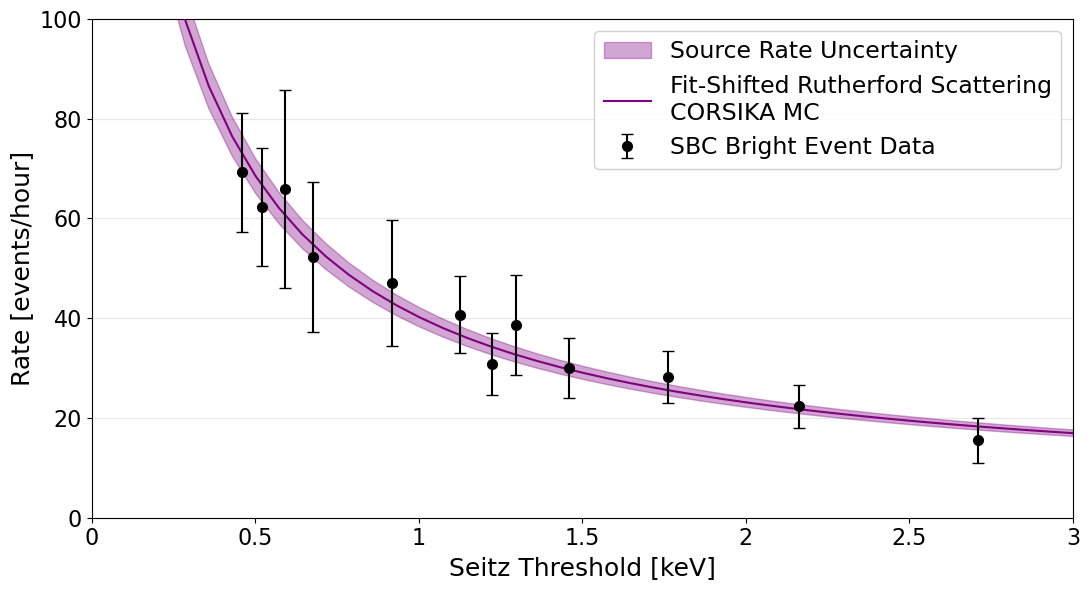

In [55]:
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d



# MC interpolation

mc_interp = interp1d(mc_thresholds,mc_total,kind="linear")


def fit_model(T, a, B):
    return mc_interp(a * T) + B


popt, pcov = curve_fit(
    fit_model,
    pset_thresholds,
    data_total,
    sigma=data_err_total,
    absolute_sigma=True,
)

a_fit, B_fit = popt

a_err, B_err = np.sqrt(np.diag(pcov))


fit_prediction = fit_model(
    pset_thresholds,
    a_fit,
    B_fit,
)


residuals = data_total - fit_prediction

chi2 = np.sum((residuals / data_err_total) ** 2)
ndf = len(data_total) - len(popt)
chi2_ndf = chi2 / ndf



print("Fit:")
print("Model: Data(T) = MC(a*T) + B")

print(f"a = {a_fit:.6f} +/- {a_err:.6f}")
print(f"B = {B_fit:.6f} +/- {B_err:.6f}")

print(f"chi^2 = {chi2:.3f}")
print(f"ndf = {ndf}")
print(f"chi^2 / ndf = {chi2_ndf:.3f}")





# SHIFT MC 

shifted_mc_thresholds = mc_thresholds / a_fit
shifted_mc_total = mc_total + B_fit

shifted_mc_err_total = mc_err_total





fig, ax = plt.subplots(figsize=(11, 6))



# Original MC

'''
ax.plot(
    mc_thresholds,
    mc_total,
    color="purple",
    linewidth=1.5,
    alpha=0.35,
    zorder=2,
    label="Original CORSIKA MC",
)
'''


# Shifted MC uncertainty

ax.fill_between(
    shifted_mc_thresholds,
    shifted_mc_total - shifted_mc_err_total,
    shifted_mc_total + shifted_mc_err_total,
    color="purple",
    alpha=0.35,
    zorder=2,
    label="Source Rate Uncertainty",
)



# Shifted MC

ax.plot(
    shifted_mc_thresholds,
    shifted_mc_total,
    color="purple",
    linewidth=1.5,
    zorder=3,
    label=(
        "Fit-Shifted Rutherford Scattering\n"
        "CORSIKA MC"
    ),
)



# Original data points

ax.errorbar(
    pset_thresholds,
    data_total,
    yerr=data_err_total,
    fmt="o",
    color="black",
    markerfacecolor="black",
    markeredgecolor="black",
    markersize=7,
    capsize=4,
    linewidth=1.5,
    zorder=5,
    label="SBC Bright Event Data",
)




ax.set_xlabel(
    "Seitz Threshold [keV]",
    fontsize=18,
)

ax.set_ylabel(
    "Rate [events/hour]",
    fontsize=18,
)



even_ticks = np.arange(0, 3.5, 0.5)

ax.set_xticks(even_ticks)
ax.set_xticklabels([f"{t:g}" for t in even_ticks])


ax.set_xlim(0, 3)

ax.set_ylim(0,100)

ax.tick_params(
    axis="both",
    labelsize=16,
)

ax.grid(
    axis="y",
    alpha=0.3,
    zorder=0,
)


ax.legend(
    fontsize=17,
    loc="upper right",
    frameon=True,
    framealpha=0.9,
)


plt.savefig("RutherfordRate_fit_MC_shifted.png")

plt.tight_layout()
plt.show()